# Day 31 | Split Long Text Into Useful Chunks

**KGP Talkie**

Choose chunk size, overlap, and metadata before building search.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

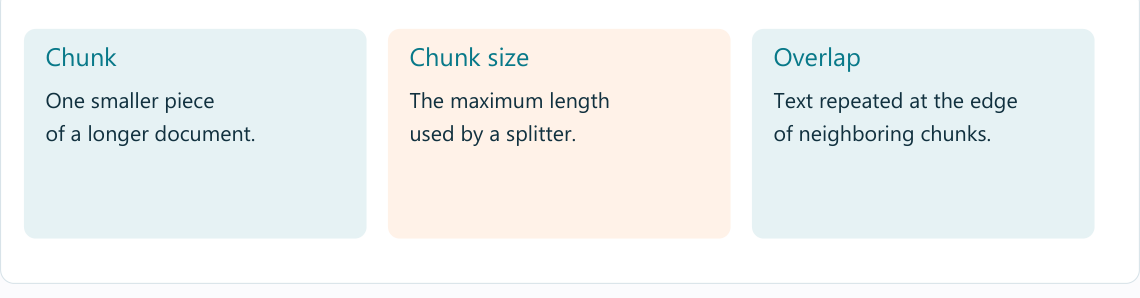

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [5]:
text = (ASSETS / "notes.txt").read_text(encoding="utf-8")

This splitter measures characters by default. 180 and 30 keep our short classroom cuts visible.

In [6]:
splitter = RecursiveCharacterTextSplitter(chunk_size=180, chunk_overlap=30)

In [7]:
chunks = splitter.create_documents([text], metadatas=[{"source": "notes.txt"}])

Print boundaries, not just the count. Overlap may be shorter when the splitter keeps natural breaks.

In [8]:
for i, chunk in enumerate(chunks):
    print(i, len(chunk.page_content), repr(chunk.page_content))

0 159 'Python class is on Monday at 10:00 in Room 2.\nPandas class is on Tuesday at 11:00 in Room 3.\nBring a laptop to both classes.\nThe class notes do not give a fee.'
1 71 'Python lists store many items. Pandas DataFrames hold rows and columns.'
2 159 'Python class is on Monday at 10:00 in Room 2.\nPandas class is on Tuesday at 11:00 in Room 3.\nBring a laptop to both classes.\nThe class notes do not give a fee.'
3 71 'Python lists store many items. Pandas DataFrames hold rows and columns.'


In [9]:
larger = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=30).split_text(text)

In [10]:
print("First size:", len(chunks), "chunks; larger size:", len(larger), "chunks")

First size: 4 chunks; larger size: 2 chunks


In [11]:
fresh = splitter.split_text("One short sentence about a new workshop.")
print(fresh)

['One short sentence about a new workshop.']


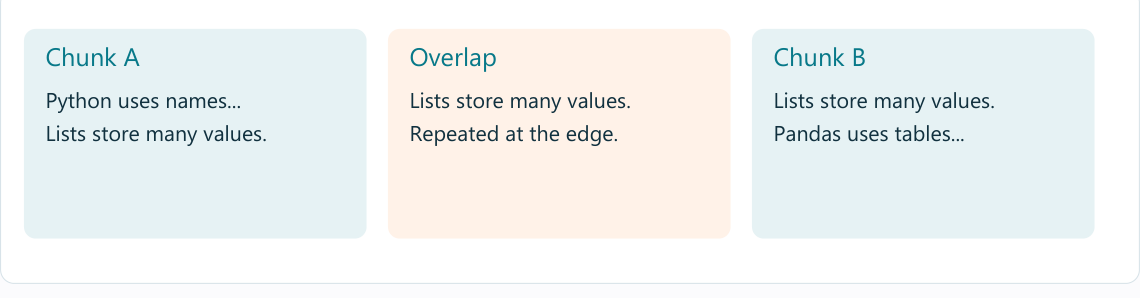

## Try a fresh input

Change one value at a time. Check whether a full answer sentence stays together.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-vector-stores).